# Clustering de texto y clustering jerárquico

```
Textos → TF-IDF → K-Means / Jerárquico → Visualización → Evaluación
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)
spanish_stopwords = stopwords.words('spanish')

## 1. Datos de texto

In [2]:
documentos = [
    # Deportes
    "El equipo ganó el partido de fútbol en el último minuto",
    "El jugador anotó tres goles en el torneo",
    "El entrenador cambió la táctica a mitad del juego",
    "El estadio estaba lleno de aficionados emocionados",
    "El árbitro cobró un penalti muy polémico",
    "El equipo local ganó el campeonato nacional",

    # Tecnología
    "La inteligencia artificial revoluciona la industria del software",
    "El nuevo modelo de lenguaje genera texto muy convincente",
    "Python es el lenguaje más popular para ciencia de datos",
    "Las redes neuronales aprenden patrones complejos en los datos",
    "El procesador tiene ocho núcleos y mucha memoria RAM",
    "La nube permite almacenar datos de forma escalable",

    # Cocina
    "La receta lleva harina, huevos y mantequilla fresca",
    "El chef preparó una salsa con tomate y albahaca",
    "El horno debe precalentarse a 180 grados antes de hornear",
    "La pasta se cuece en agua con sal durante ocho minutos",
    "El postre de chocolate quedó esponjoso y delicioso",
    "Los ingredientes frescos hacen la diferencia en la cocina",

    # Viajes
    "El vuelo a París salió con dos horas de retraso",
    "El hotel tenía una vista increíble al mar Mediterráneo",
    "Visitamos museos y restaurantes típicos de la ciudad",
    "El pasaporte vence el próximo año y hay que renovarlo",
    "La maleta fue perdida por la aerolínea en el aeropuerto",
    "El tren de alta velocidad conecta las dos ciudades en una hora",
]

# Temas reales: solo para evaluar al final, el algoritmo nunca los ve
temas_reales = ['Deportes'] * 6 + ['Tecnología'] * 6 + ['Cocina'] * 6 + ['Viajes'] * 6

print(f"Total de documentos: {len(documentos)}")

Total de documentos: 24


## 2. Vectorización con TF-IDF

In [3]:
def vectorizar(textos, max_features=100):
    """Convierte textos en una matriz TF-IDF, quitando stopwords en español."""
    vec = TfidfVectorizer(max_features=max_features, stop_words=spanish_stopwords)
    return vec.fit_transform(textos), vec

X, vectorizador = vectorizar(documentos)

print(f"Forma de la matriz TF-IDF: {X.shape}")
print(f"→ {X.shape[0]} documentos  x  {X.shape[1]} palabras")
print("\nAlgunas palabras del vocabulario (con stopwords eliminadas):")
print(vectorizador.get_feature_names_out()[:20])

Forma de la matriz TF-IDF: (24, 100)
→ 24 documentos  x  100 palabras

Algunas palabras del vocabulario (con stopwords eliminadas):
['180' 'aerolínea' 'aeropuerto' 'aficionados' 'agua' 'albahaca'
 'almacenar' 'alta' 'anotó' 'aprenden' 'artificial' 'año' 'cambió'
 'campeonato' 'chef' 'chocolate' 'ciencia' 'ciudad' 'ciudades' 'cobró']


Ahora el `TfidfVectorizer` usa las stopwords en español. Esto elimina palabras muy frecuentes como *el*, *de* o *con*, que no ayudan a distinguir un tema de otro.

## 3. K-Means sobre texto

In [4]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
etiquetas = kmeans.fit_predict(X)

for c in range(K):
    print(f"\nCluster {c}:")
    for i, doc in enumerate(documentos):
        if etiquetas[i] == c:
            print(f"   • {doc}")


Cluster 0:
   • El vuelo a París salió con dos horas de retraso
   • El tren de alta velocidad conecta las dos ciudades en una hora

Cluster 1:
   • El equipo ganó el partido de fútbol en el último minuto
   • El equipo local ganó el campeonato nacional

Cluster 2:
   • El jugador anotó tres goles en el torneo
   • El entrenador cambió la táctica a mitad del juego
   • El estadio estaba lleno de aficionados emocionados
   • El árbitro cobró un penalti muy polémico
   • La inteligencia artificial revoluciona la industria del software
   • El procesador tiene ocho núcleos y mucha memoria RAM
   • La receta lleva harina, huevos y mantequilla fresca
   • El chef preparó una salsa con tomate y albahaca
   • El horno debe precalentarse a 180 grados antes de hornear
   • La pasta se cuece en agua con sal durante ocho minutos
   • El postre de chocolate quedó esponjoso y delicioso
   • Los ingredientes frescos hacen la diferencia en la cocina
   • El hotel tenía una vista increíble al mar Med

Comparemos los clusters con los temas reales. Una tabla cruzada muestra qué tema cayó en cada cluster, y el *Adjusted Rand Index* (ARI) resume el acuerdo: 1 es coincidencia perfecta y valores cercanos a 0 son azar.

In [5]:
tabla = pd.crosstab(
    pd.Series(etiquetas, name='Cluster'),
    pd.Series(temas_reales, name='Tema real'),
)
print(tabla)
print(f"\nAdjusted Rand Index: {adjusted_rand_score(temas_reales, etiquetas):.3f}")

Tema real  Cocina  Deportes  Tecnología  Viajes
Cluster                                        
0               0         0           0       2
1               0         2           0       0
2               6         4           2       4
3               0         0           4       0

Adjusted Rand Index: 0.124


**Lectura:** el ARI es bajo (cerca de 0.12). Con 24 documentos cortos casi no comparten palabras, y el cluster 2 absorbe 16 de los 24 documentos mezclando temas. K-Means siempre devuelve grupos, aunque no tengan sentido: evaluar la calidad es parte del análisis.

## 4. ¿Qué palabras definen cada cluster?

In [6]:
terminos = vectorizador.get_feature_names_out()

print("Palabras clave por cluster:\n")
for i, centroide in enumerate(kmeans.cluster_centers_):
    top_indices = centroide.argsort()[-6:][::-1]  # top 6 palabras
    palabras = [terminos[j] for j in top_indices]
    print(f"  Cluster {i}: {', '.join(palabras)}")

Palabras clave por cluster:

  Cluster 0: dos, parís, horas, conecta, hora, alta
  Cluster 1: ganó, equipo, minuto, partido, fútbol, local
  Cluster 2: ocho, museos, ciudad, polémico, penalti, cobró
  Cluster 3: datos, lenguaje, popular, python, ciencia, genera


## 5. Visualización en 2D con PCA

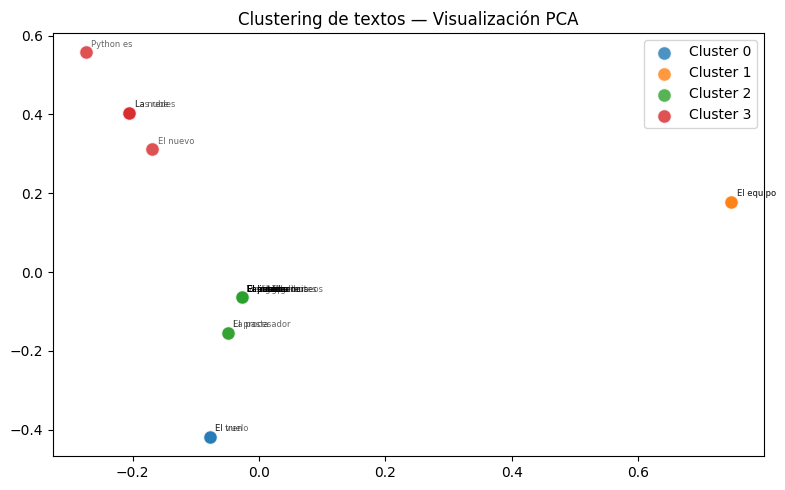

In [7]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X.toarray())

colores = plt.cm.tab10.colors

plt.figure(figsize=(8, 5))
for i in range(K):
    mascara = etiquetas == i
    plt.scatter(X_2d[mascara, 0], X_2d[mascara, 1],
                color=colores[i], label=f'Cluster {i}',
                s=100, alpha=0.8, edgecolors='white')

# Anotar cada punto con las primeras palabras del documento
for i, doc in enumerate(documentos):
    etiqueta_corta = ' '.join(doc.split()[:2])
    plt.annotate(etiqueta_corta, (X_2d[i, 0], X_2d[i, 1]),
                 fontsize=6, alpha=0.6, xytext=(4, 4), textcoords='offset points')

plt.title("Clustering de textos — Visualización PCA")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Comparar con los temas reales

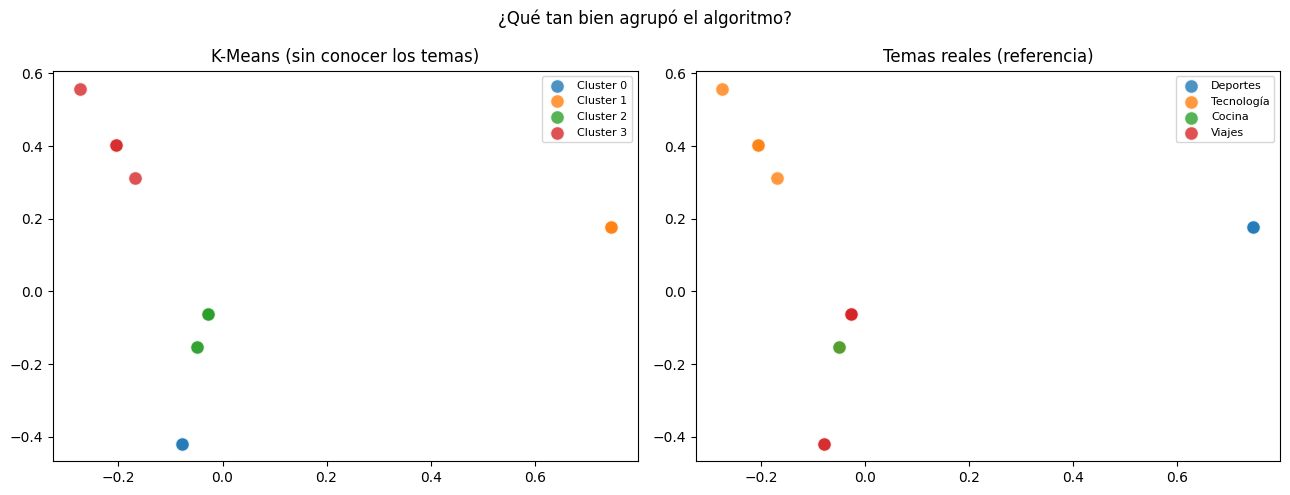

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Izquierda: clusters descubiertos por K-Means
for i in range(K):
    mascara = etiquetas == i
    axes[0].scatter(X_2d[mascara, 0], X_2d[mascara, 1],
                    color=colores[i], label=f'Cluster {i}', s=100, alpha=0.8, edgecolors='white')
axes[0].set_title("K-Means (sin conocer los temas)")
axes[0].legend(fontsize=8)

# Derecha: temas reales (los colores no tienen relación con los de la izquierda)
temas_unicos = list(dict.fromkeys(temas_reales))
for i, tema in enumerate(temas_unicos):
    mascara = np.array([t == tema for t in temas_reales])
    axes[1].scatter(X_2d[mascara, 0], X_2d[mascara, 1],
                    color=colores[i], label=tema, s=100, alpha=0.8, edgecolors='white')
axes[1].set_title("Temas reales (referencia)")
axes[1].legend(fontsize=8)

plt.suptitle("¿Qué tan bien agrupó el algoritmo?", fontsize=12)
plt.tight_layout()
plt.show()

## 7. Silhouette score

El silhouette score mide qué tan separado está cada punto de su cluster respecto a los demás:

- Cerca de **1** → clusters bien separados
- Cerca de **0** → clusters solapados
- Negativo → puntos probablemente mal asignados

Con vectores TF-IDF normalizados, la distancia euclidiana ordena los puntos igual que la similitud del coseno, así que podemos usar la métrica por defecto.

Silhouette Score (K=4): 0.034


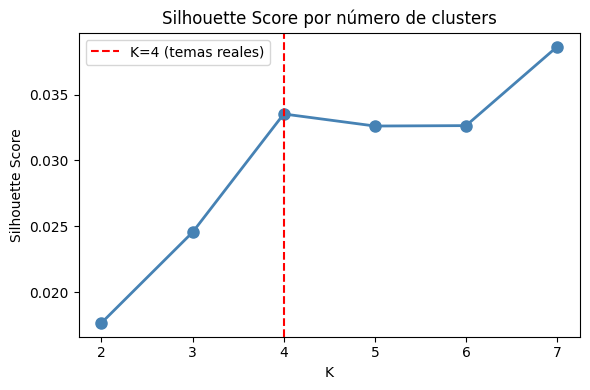

Mejor K según Silhouette: 7


In [9]:
print(f"Silhouette Score (K={K}): {silhouette_score(X, etiquetas):.3f}")

ks = list(range(2, 8))
scores = []
for k in ks:
    etiq = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
    scores.append(silhouette_score(X, etiq))

plt.figure(figsize=(6, 4))
plt.plot(ks, scores, 'o-', color='steelblue', linewidth=2, markersize=8)
plt.axvline(x=4, color='red', linestyle='--', label='K=4 (temas reales)')
plt.title("Silhouette Score por número de clusters")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Mejor K según Silhouette: {ks[int(np.argmax(scores))]}")

**Lectura:** con este corpus el silhouette no señala K=4 como óptimo: el máximo cae en K=7 y, para K=4, el valor es apenas 0.03. Es otra señal de que hay muy pocos textos para un análisis confiable.

## 8. Clustering jerárquico: estados de EE.UU.

Ahora un ejemplo clásico de clustering jerárquico, ya sin texto. El conjunto de datos `USArrests` viene de R (James et al., *An Introduction to Statistical Learning*) y tiene, para cada uno de los 50 estados de EE.UU. en 1973:

- **Murder**, **Assault** y **Rape**: arrestos por cada 100 000 habitantes
- **UrbanPop**: porcentaje de población urbana

Pregunta: ¿qué estados se parecen entre sí en su perfil de criminalidad?

In [10]:
url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/USArrests.csv"
arrests = pd.read_csv(url, index_col=0)
arrests.index.name = 'Estado'

print(arrests.shape)
arrests.head()

(50, 4)


,Murder,Assault,UrbanPop,Rape
Estado,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


Las variables están en escalas muy distintas: `Assault` va en cientos y `Murder` en unidades. Si no las estandarizamos, la distancia la domina `Assault`. Por eso escalamos cada variable a media 0 y desviación estándar 1.

In [11]:
escalador = StandardScaler()
X_estados = escalador.fit_transform(arrests)

print(pd.DataFrame(X_estados, columns=arrests.columns, index=arrests.index).describe().round(2))

       Murder  Assault  UrbanPop   Rape
count   50.00    50.00     50.00  50.00
mean    -0.00     0.00     -0.00   0.00
std      1.01     1.01      1.01   1.01
min     -1.62    -1.52     -2.34  -1.50
25%     -0.86    -0.75     -0.77  -0.66
50%     -0.12    -0.14      0.03  -0.12
75%      0.80     0.95      0.85   0.53
max      2.23     2.02      1.78   2.67


El método `linkage` construye el árbol de fusiones. Usamos `complete` (distancia máxima entre clusters). El dendrograma muestra la historia completa de fusiones: cortarlo a distinta altura da distinto número de clusters.

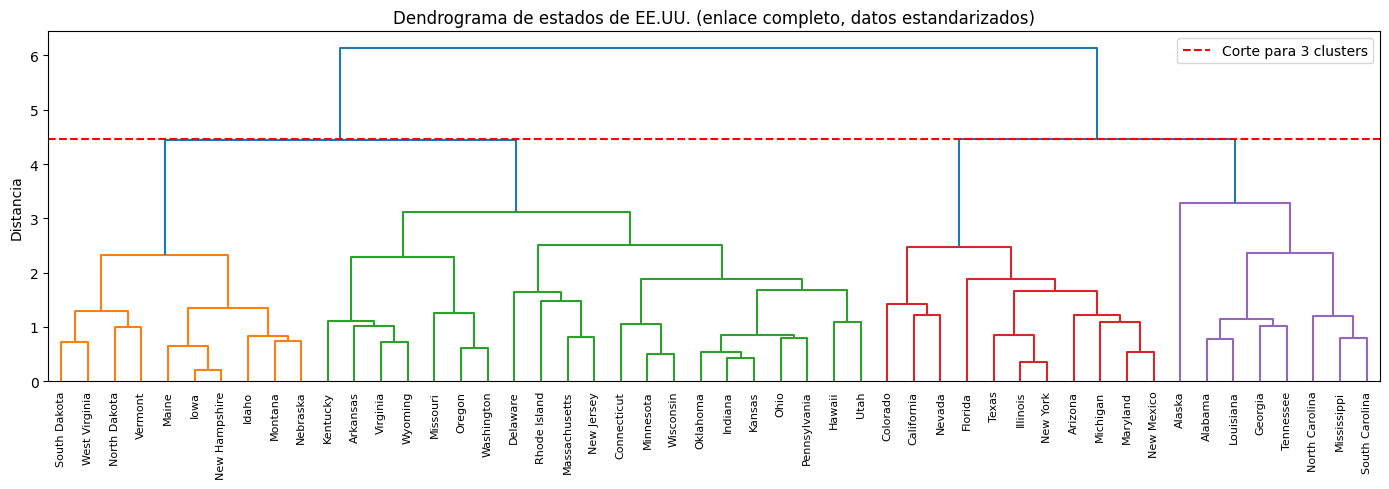

In [12]:
Z = linkage(X_estados, method='complete')

# Altura de corte que deja 3 clusters: a la mitad entre las dos últimas fusiones
altura_corte = (Z[-2, 2] + Z[-3, 2]) / 2

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, labels=arrests.index.tolist(), leaf_rotation=90, leaf_font_size=8, ax=ax)
ax.axhline(y=altura_corte, color='red', linestyle='--', label='Corte para 3 clusters')
ax.set_title("Dendrograma de estados de EE.UU. (enlace completo, datos estandarizados)")
ax.set_ylabel("Distancia")
ax.legend()
plt.tight_layout()
plt.show()

Cortamos el dendrograma para obtener 3 grupos y revisamos el promedio de cada variable en cada grupo para interpretarlos:

In [13]:
grupos = fcluster(Z, t=3, criterion='maxclust')

resultado = arrests.assign(Grupo=grupos)
print("Estados por grupo:")
print(resultado['Grupo'].value_counts().sort_index())
print("\nPromedio de cada variable por grupo:")
print(resultado.groupby('Grupo').mean().round(1))

Estados por grupo:
Grupo
1    31
2    11
3     8
Name: count, dtype: int64

Promedio de cada variable por grupo:
       Murder  Assault  UrbanPop  Rape
Grupo                                 
1         5.0    116.5      63.8  16.3
2        11.1    264.1      79.1  32.6
3        14.1    252.8      53.5  24.5


**Lectura:**
- **Grupo 1** (31 estados): tasas bajas en todos los delitos (Murder de 5.0).
- **Grupo 2** (11 estados): Murder, Assault y Rape altos, y el porcentaje urbano más alto (79%).
- **Grupo 3** (8 estados): Murder y Assault altos, pero menos urbanizados (54%).

Ahora comparamos con K-Means en los mismos datos estandarizados. Si los dos métodos coinciden, la estructura es robusta; si no, conviene investigar por qué.

In [14]:
km_estados = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_estados)
print(f"Adjusted Rand Index (jerárquico vs K-Means): {adjusted_rand_score(grupos, km_estados):.3f}")

Adjusted Rand Index (jerárquico vs K-Means): 0.388


El acuerdo es moderado (ARI cerca de 0.39): los dos métodos coinciden en parte, pero no del todo. Es normal, porque el dendrograma y K-Means optimizan criterios distintos.

Visualicemos los estados en las dos primeras componentes principales, coloreados por grupo jerárquico:

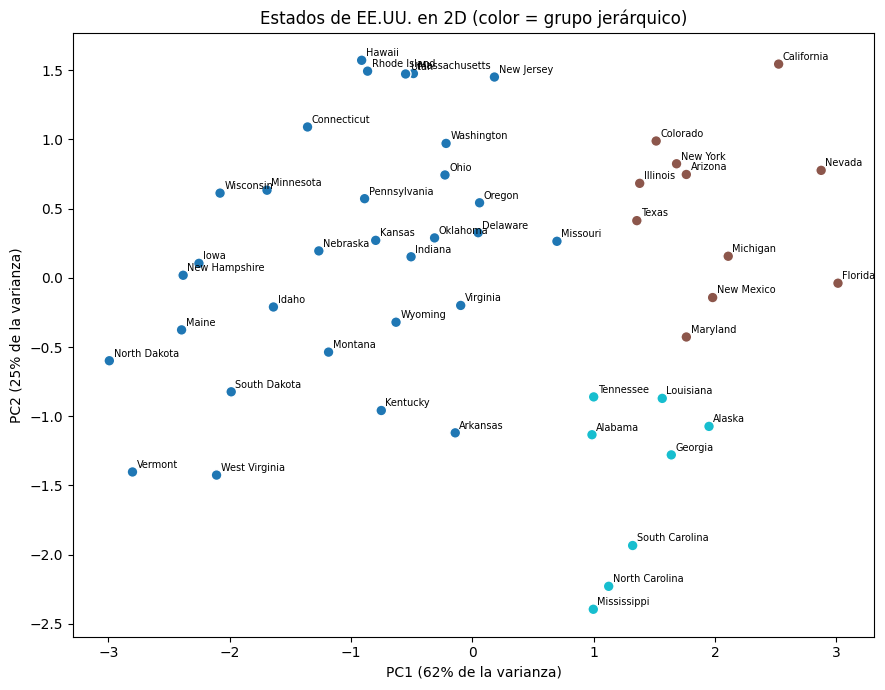

In [15]:
pca_estados = PCA(n_components=2)
coords = pca_estados.fit_transform(X_estados)

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(coords[:, 0], coords[:, 1], c=grupos, cmap='tab10', s=60, edgecolors='white')
for (x, y), estado in zip(coords, arrests.index):
    ax.annotate(estado, (x, y), fontsize=7, xytext=(3, 3), textcoords='offset points')

varianza = pca_estados.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({varianza[0]:.0%} de la varianza)")
ax.set_ylabel(f"PC2 ({varianza[1]:.0%} de la varianza)")
ax.set_title("Estados de EE.UU. en 2D (color = grupo jerárquico)")
plt.tight_layout()
plt.show()

**Ejercicio:** repite el dendrograma con `X = arrests.values` (sin `StandardScaler`). ¿Cambian los grupos? ¿Qué variable domina la distancia?

## 9. Agrega tus propios textos

In [16]:
def agrupar(textos, n_clusters):
    """Vectoriza y agrupa textos con K-Means. Devuelve las etiquetas."""
    X_nuevo, _ = vectorizar(textos)
    km = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
    return km.fit_predict(X_nuevo)

mis_textos = [
    "El perro corre por el parque feliz",
    "El gato duerme en el sofá todo el día",
    "La bolsa de valores subió hoy tres puntos",
    "El banco central subió las tasas de interés",
    "La película ganó el premio en el festival",
    "El actor protagonizó la nueva serie de televisión",
]

N_CLUSTERS = 3   # ← cambia esto

etiq = agrupar(mis_textos, N_CLUSTERS)
for c in range(N_CLUSTERS):
    print(f"\nCluster {c}:")
    for i, t in enumerate(mis_textos):
        if etiq[i] == c:
            print(f"   • {t}")


Cluster 0:
   • El perro corre por el parque feliz
   • El gato duerme en el sofá todo el día
   • El actor protagonizó la nueva serie de televisión

Cluster 1:
   • La bolsa de valores subió hoy tres puntos
   • El banco central subió las tasas de interés

Cluster 2:
   • La película ganó el premio en el festival


## Resumen del flujo

```
1. Textos en español
      ↓
2. TfidfVectorizer  →  matriz numérica (docs × palabras)
      ↓
3. KMeans  →  etiqueta por documento
      ↓
4. PCA (2D)  →  visualización
      ↓
5. Silhouette / ARI  →  evaluar calidad

Clustering jerárquico (estados): estandarizar → linkage → dendrograma → cortar
```